# Project 1 — Bank Marketing: Subscription Prediction
**Student:** Pius OGWAL | **Access number:** B34982  
**Course:** DSC8307 — Data Mining, Modeling and Analytics | **Advent 2026**

## Research question
Which modeling approach most effectively identifies likely term-deposit subscribers, and what probability threshold balances avoidable calls against missed subscribers?

**Design:** stratified train/validation/test partition; preprocessing fitted on training data only; majority-class baseline; three candidate classifiers; cross-validation and randomized hyperparameter search; threshold selection on validation data; one final held-out test evaluation; sensitivity and subgroup diagnostics.

**Interpretation safeguard:** `duration` (call duration) is excluded because it is not available before the call and would leak post-contact information into a pre-call decision. Campaign variables may also depend on when a prediction is made; the notebook describes this limitation.

**Sources:** Moro, Cortez & Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, Decision Support Systems 62, 22–31; UCI Bank Marketing dataset; scikit-learn documentation.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from scipy.stats import randint, loguniform
import warnings
SEED=42
sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT / 'DSC8307_Pius_OGWAL' / 'data').exists(): ROOT = ROOT / 'DSC8307_Pius_OGWAL'
DATA=ROOT/'data'; DATA.mkdir(exist_ok=True,parents=True)
FIG=ROOT/'figures'; FIG.mkdir(exist_ok=True,parents=True)
print('Working directory:',ROOT)

Working directory: /mnt/data/DSC8307_Pius_OGWAL


## 1. Load and audit the data

In [2]:
import io, zipfile, urllib.request
path=DATA/'bank-additional-full.csv'
if path.exists():
    bank=pd.read_csv(path,sep=';')
else:
    print('Local CSV not found; attempting the official UCI dataset archive.')
    url='https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
    try:
        raw=urllib.request.urlopen(url,timeout=40).read()
        def find_csv(blob):
            with zipfile.ZipFile(io.BytesIO(blob)) as z:
                for filename in z.namelist():
                    if filename.lower().endswith('bank-additional-full.csv'):
                        return z.read(filename)
                for filename in z.namelist():
                    if filename.lower().endswith('.zip'):
                        result=find_csv(z.read(filename))
                        if result is not None:return result
            return None
        csv_bytes=find_csv(raw)
        if csv_bytes is None: raise FileNotFoundError('CSV missing from archive')
        path.write_bytes(csv_bytes)
        bank=pd.read_csv(path,sep=';')
    except Exception as exc:
        raise FileNotFoundError('Put bank-additional-full.csv in data/ and rerun. Automatic UCI retrieval failed: '+str(exc)) from exc
assert 'y' in bank.columns
bank['y']=bank['y'].astype(str).str.strip().str.lower()
assert set(bank['y'].unique()).issubset({'yes','no'})
display(bank.head())
print('Shape:',bank.shape)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Shape: (41188, 21)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values: {'age': 0, 'job': 0, 'marital': 0, 'education': 0, 'default': 0, 'housing': 0, 'loan': 0, 'contact': 0, 'month': 0, 'day_of_week': 0, 'duration': 0, 'campaign': 0, 'pdays': 0, 'previous': 0, 'poutcome': 0, 'emp.var.rate': 0, 'cons.price.idx': 0, 'cons.conf.idx': 0, 'euribor3m': 0, 'nr.employed': 0, 'y': 0}


Literal unknown categories: {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990, 'contact': 0, 'month': 0, 'day_of_week': 0, 'poutcome': 0, 'y': 0}


Exact duplicates: 12


,count,share
class,,
no,36548,0.887346
yes,4640,0.112654


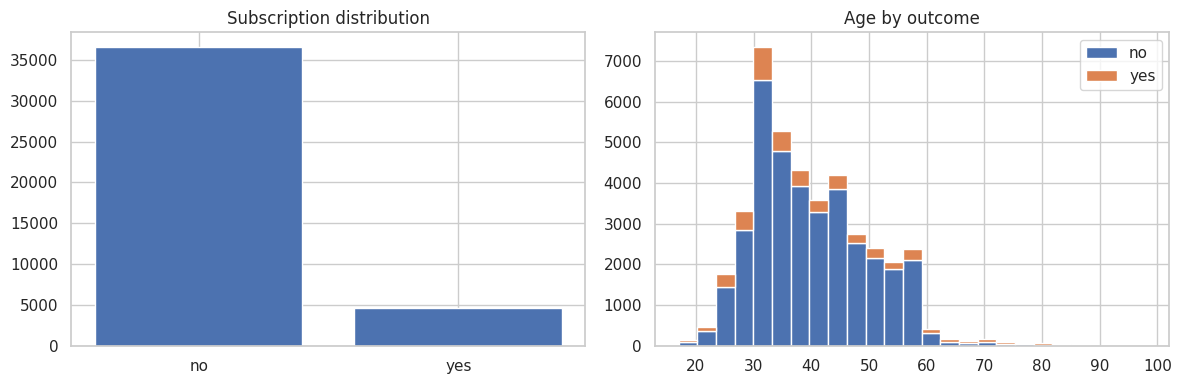

In [3]:
display(bank.info());display(bank.describe(include='all').T)
print('Missing values:',bank.isna().sum().to_dict())
print('Literal unknown categories:',{c:int((bank[c].astype(str).str.lower()=='unknown').sum()) for c in bank.select_dtypes('object').columns})
print('Exact duplicates:',bank.duplicated().sum())
display(bank['y'].value_counts().rename_axis('class').to_frame('count').assign(share=lambda x:x['count']/len(bank)))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(bank['y'].value_counts().index,bank['y'].value_counts().values);axes[0].set_title('Subscription distribution')
if 'age' in bank:axes[1].hist([bank.loc[bank.y=='no','age'],bank.loc[bank.y=='yes','age']],bins=25,stacked=True,label=['no','yes']);axes[1].legend();axes[1].set_title('Age by outcome')
plt.tight_layout();plt.show()

### Data preparation rationale
- The target is converted to binary (`yes` = 1).
- Literal `unknown` values are treated as missing for categorical predictors, then imputed and one-hot encoded inside the fitted pipeline; this avoids treating an unspecified answer as an ordinary category without consideration.
- Numeric predictors use median imputation; numeric scaling benefits the regularized logistic model.
- Exact duplicates are **reported but retained** because identical records can represent different customers and no customer identifier is supplied.
- `duration` is excluded for pre-call use. A random stratified split estimates performance on similar records; temporal drift and repeated-customer leakage cannot be fully ruled out without identifiers and campaign dates.
- No resampling is applied initially: class imbalance is addressed using PR-AUC, recall, precision, class weights for logistic regression, and threshold choice.

In [4]:
target=bank['y'].eq('yes').astype(int)
X=bank.drop(columns=['y','duration'],errors='ignore').copy()
for c in X.select_dtypes(include=['object','category']).columns:X[c]=X[c].replace('unknown',np.nan)
X_dev,X_test,y_dev,y_test=train_test_split(X,target,test_size=.20,random_state=SEED,stratify=target)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,random_state=SEED,stratify=y_dev)
print('Train/validation/test:',len(X_train),len(X_val),len(X_test));print('Positive prevalence:',[round(y.mean(),4) for y in (y_train,y_val,y_test)])
cat=X.select_dtypes(include=['object','category']).columns.tolist();num=X.select_dtypes(exclude=['object','category']).columns.tolist()
pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)],sparse_threshold=0)

Train/validation/test: 24712 8238 8238
Positive prevalence: [np.float64(0.1127), np.float64(0.1126), np.float64(0.1126)]


## 2. Baseline and model comparison

In [5]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
models={
 'Logistic regression':Pipeline([('pre',pre),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))]),
 'Random forest':Pipeline([('pre',pre),('model',RandomForestClassifier(n_estimators=250,min_samples_leaf=3,n_jobs=-1,random_state=SEED))]),
 'Gradient boosting':Pipeline([('pre',pre),('model',HistGradientBoostingClassifier(max_iter=150,learning_rate=.07,random_state=SEED))])
}
baseline=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
def clf_metrics(y,p,threshold=.5):
    label=(p>=threshold).astype(int)
    return {'accuracy':accuracy_score(y,label),'balanced_accuracy':balanced_accuracy_score(y,label),'precision':precision_score(y,label,zero_division=0),'recall':recall_score(y,label,zero_division=0),'F1':f1_score(y,label,zero_division=0),'ROC_AUC':roc_auc_score(y,p),'PR_AUC':average_precision_score(y,p),'Brier':brier_score_loss(y,p)}
base_p=baseline.predict_proba(X_val)[:,list(baseline.classes_).index(1)] if 1 in baseline.classes_ else np.zeros(len(y_val))
rows=[{'model':'Majority baseline','CV_PR_AUC_mean':np.nan,'CV_PR_AUC_sd':np.nan,**clf_metrics(y_val,base_p)}]
cv_results={}
for name,model in models.items():
    scores=cross_validate(model,X_train,y_train,cv=cv,scoring={'pr_auc':'average_precision','roc_auc':'roc_auc','f1':'f1'},n_jobs=-1)
    cv_results[name]=scores
    model.fit(X_train,y_train)
    rows.append({'model':name,'CV_PR_AUC_mean':scores['test_pr_auc'].mean(),'CV_PR_AUC_sd':scores['test_pr_auc'].std(),**clf_metrics(y_val,model.predict_proba(X_val)[:,1])})
comparison=pd.DataFrame(rows).sort_values('PR_AUC',ascending=False)
display(comparison.round(4))
print('Model ranking uses validation PR-AUC, supplemented by CV PR-AUC and practical trade-offs; accuracy alone is misleading with imbalance.')

,model,CV_PR_AUC_mean,CV_PR_AUC_sd,accuracy,balanced_accuracy,precision,recall,F1,ROC_AUC,PR_AUC,Brier
3,Gradient boosting,0.4611,0.0336,0.9011,0.6154,0.6638,0.2468,0.3598,0.8100,0.4697,0.0771
2,Random forest,0.4579,0.0335,0.9002,0.6225,0.6380,0.2640,0.3735,0.7976,0.4618,0.0778
1,Logistic regression,0.4448,0.0273,0.8264,0.7390,0.3492,0.6261,0.4483,0.7997,0.4417,0.1658
0,Majority baseline,NaN,NaN,0.8874,0.5000,0.0000,0.0000,0.0000,0.5000,0.1126,0.1126


Model ranking uses validation PR-AUC, supplemented by CV PR-AUC and practical trade-offs; accuracy alone is misleading with imbalance.


### Model selection: empirical answer
Three candidate classifiers were compared because they offer complementary assumptions: regularized logistic regression provides an interpretable linear log-odds benchmark, random forest accommodates nonlinear interactions, and histogram gradient boosting builds additive nonlinear corrections. **Validation PR-AUC ranks gradient boosting first (0.4697), random forest second (0.4618), and logistic regression third (0.4417).** The corresponding five-fold training CV means are approximately 0.4611, 0.4579, and 0.4448. Because subscriptions are uncommon (11.27%), PR-AUC is more decision-relevant than accuracy alone; the majority-class baseline achieves only approximately 0.1126 validation PR-AUC. The small gaps between the leading models do not establish statistically significant superiority. Gradient boosting is selected by the prespecified validation criterion, not by its test score. The test partition is evaluated only after selection.

## 3. Threshold selection and cost sensitivity

Selected model: Gradient boosting | illustrative FP:FN cost ratio = 1.0:5.0
Recommended threshold under illustrative assumptions: 0.175


,threshold,TP,FP_unnecessary_calls,FN_missed_subscribers,TN,precision,recall,F1,calls,illustrative_cost
5,0.175,548,733,380,6577,0.428,0.591,0.496,1281,2633.0
4,0.150,554,803,374,6507,0.408,0.597,0.485,1357,2673.0
7,0.225,516,615,412,6695,0.456,0.556,0.501,1131,2675.0
6,0.200,524,662,404,6648,0.442,0.565,0.496,1186,2682.0
3,0.125,573,919,355,6391,0.384,0.617,0.474,1492,2694.0
8,0.250,498,570,430,6740,0.466,0.537,0.499,1068,2720.0
2,0.100,613,1167,315,6143,0.344,0.661,0.453,1780,2742.0
9,0.275,480,528,448,6782,0.476,0.517,0.496,1008,2768.0
10,0.300,461,489,467,6821,0.485,0.497,0.491,950,2824.0
11,0.325,422,414,506,6896,0.505,0.455,0.478,836,2944.0


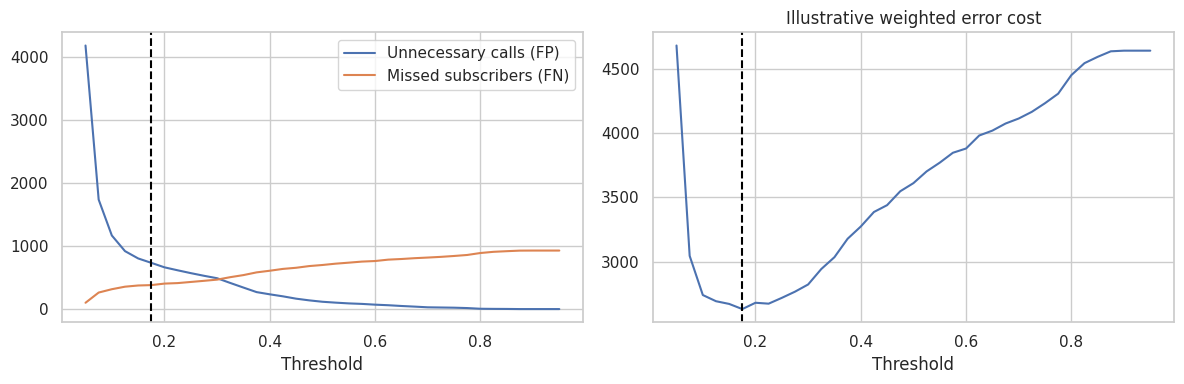

In [6]:
best_name=comparison.loc[comparison['model']!='Majority baseline','model'].iloc[0]
best=models[best_name]
val_prob=best.predict_proba(X_val)[:,1]
thresholds=np.round(np.arange(.05,.951,.025),3)
trade=[]
for t in thresholds:
    pred=(val_prob>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_val,pred,labels=[0,1]).ravel()
    trade.append({'threshold':t,'TP':tp,'FP_unnecessary_calls':fp,'FN_missed_subscribers':fn,'TN':tn,'precision':precision_score(y_val,pred,zero_division=0),'recall':recall_score(y_val,pred,zero_division=0),'F1':f1_score(y_val,pred,zero_division=0),'calls':int(pred.sum())})
trade=pd.DataFrame(trade)
# Illustrative decision assumption, NOT an observed bank cost: missed subscription opportunity = 5 times unnecessary call cost.
C_FP=1.0;C_FN=5.0
trade['illustrative_cost']=C_FP*trade['FP_unnecessary_calls']+C_FN*trade['FN_missed_subscribers']
chosen=trade.loc[trade['illustrative_cost'].idxmin()]
print('Selected model:',best_name,'| illustrative FP:FN cost ratio =',f'{C_FP}:{C_FN}')
print('Recommended threshold under illustrative assumptions:',chosen['threshold'])
display(trade.sort_values('illustrative_cost').head(10).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(trade.threshold,trade.FP_unnecessary_calls,label='Unnecessary calls (FP)');axes[0].plot(trade.threshold,trade.FN_missed_subscribers,label='Missed subscribers (FN)');axes[0].axvline(chosen.threshold,color='black',ls='--');axes[0].legend();axes[0].set_xlabel('Threshold')
axes[1].plot(trade.threshold,trade.illustrative_cost);axes[1].axvline(chosen.threshold,color='black',ls='--');axes[1].set_title('Illustrative weighted error cost');axes[1].set_xlabel('Threshold')
plt.tight_layout();plt.show()

### Threshold decision and operational interpretation
**Recommended research threshold: 0.175**, chosen on the validation set under the explicitly *illustrative* cost assumption that a missed subscriber has five times the cost of an unnecessary call. At this cutoff, the validation sample yields **548 true positives, 733 false positives, and 380 false negatives**, with **1,281 customers flagged**. Thus the policy retrieves 548 of 928 observed subscribers (recall ≈ 59.1%), while 548 of 1,281 flagged customers subscribe (precision ≈ 42.8%); 733 flagged customers do not subscribe. These are predictive classifications, **not** estimates of causal conversion uplift. Lower cutoffs generally increase recall and call volume; higher cutoffs reduce calls at the cost of more missed subscribers. The cost-ratio sensitivity table directly above shows that the selected cutoff changes with the relative costs. No bank-provided call costs, customer lifetime values, or capacity constraints were available; therefore 0.175 is a defensible **scenario-based recommendation**, not a verified profit-maximizing operating policy. Before deployment, validate probability calibration, operational costs, capacity, consent requirements and incremental campaign lift.

In [7]:
cost_sensitivity=[]
for ratio in [1,2,5,10,20]:
    costs=trade.FP_unnecessary_calls+ratio*trade.FN_missed_subscribers
    winner=trade.loc[costs.idxmin()]
    cost_sensitivity.append({'missed_to_call_cost_ratio':ratio,'best_threshold':winner.threshold,'calls':winner.calls,'false_positives':winner.FP_unnecessary_calls,'false_negatives':winner.FN_missed_subscribers})
display(pd.DataFrame(cost_sensitivity))

,missed_to_call_cost_ratio,best_threshold,calls,false_positives,false_negatives
0,1,0.500,345.0,116.0,699.0
1,2,0.350,730.0,341.0,539.0
2,5,0.175,1281.0,733.0,380.0
3,10,0.100,1780.0,1167.0,315.0
4,20,0.050,5008.0,4180.0,100.0


## 4. Final held-out test evaluation and diagnostics

,model,threshold,accuracy,balanced_accuracy,precision,recall,F1,ROC_AUC,PR_AUC,Brier
0,Gradient boosting,0.175,0.8744,0.7594,0.4569,0.611,0.5228,0.8081,0.4826,0.0753


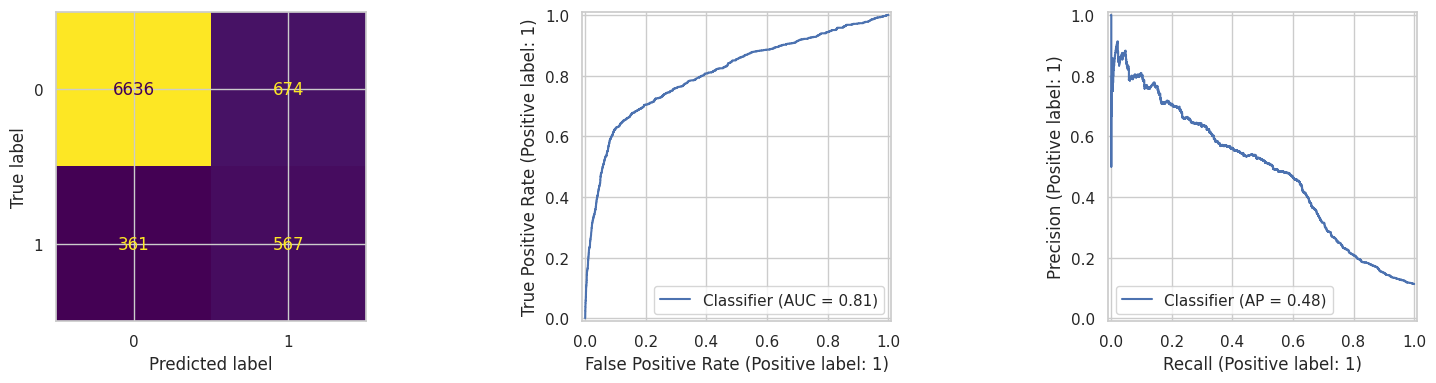

Bootstrap 95% percentile intervals for [PR-AUC, ROC-AUC]: [[0.452 0.791]
 [0.516 0.824]]


In [8]:
test_prob=best.predict_proba(X_test)[:,1]
final_metrics=clf_metrics(y_test,test_prob,float(chosen.threshold))
display(pd.DataFrame([{'model':best_name,'threshold':chosen.threshold,**final_metrics}]).round(4))
fig,ax=plt.subplots(1,3,figsize=(16,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_prob>=chosen.threshold,ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,test_prob,ax=ax[1]);PrecisionRecallDisplay.from_predictions(y_test,test_prob,ax=ax[2]);plt.tight_layout();plt.show()
# Bootstrap uncertainty conditional on the already selected fitted model.
rng=np.random.default_rng(SEED);idx=np.arange(len(y_test));boot=[]
for _ in range(500):
    sample=rng.choice(idx,size=len(idx),replace=True)
    if len(np.unique(y_test.iloc[sample]))<2:continue
    boot.append([average_precision_score(y_test.iloc[sample],test_prob[sample]),roc_auc_score(y_test.iloc[sample],test_prob[sample])])
print('Bootstrap 95% percentile intervals for [PR-AUC, ROC-AUC]:',np.percentile(boot,[2.5,97.5],axis=0).round(3))

In [9]:
# Group-level descriptive audit; these are diagnostic, not causal comparisons.
for group in ['age','job','education']:
    if group not in X_test:continue
    g=pd.cut(X_test[group],bins=[0,30,45,60,120],include_lowest=True) if group=='age' else X_test[group].fillna('Missing')
    audit=pd.DataFrame({'group':g.astype(str),'true':y_test.to_numpy(),'score':test_prob,'pred':test_prob>=chosen.threshold})
    result=audit.groupby('group').agg(n=('true','size'),actual_rate=('true','mean'),predicted_positive_rate=('pred','mean'))
    display(result[result.n>=30].sort_values('n',ascending=False).round(3).head(12))

,n,actual_rate,predicted_positive_rate
group,,,
"(30.0, 45.0]",4438,0.096,0.104
"(45.0, 60.0]",2172,0.096,0.120
"(-0.001, 30.0]",1444,0.145,0.235
"(60.0, 120.0]",184,0.457,0.978


,n,actual_rate,predicted_positive_rate
group,,,
admin.,2108,0.134,0.187
blue-collar,1813,0.068,0.047
technician,1343,0.108,0.131
services,773,0.089,0.082
management,579,0.102,0.147
retired,354,0.243,0.497
self-employed,322,0.093,0.149
entrepreneur,296,0.081,0.081
unemployed,216,0.130,0.204


,n,actual_rate,predicted_positive_rate
group,,,
university.degree,2432,0.134,0.213
high.school,1919,0.113,0.142
basic.9y,1219,0.085,0.066
professional.course,1051,0.116,0.139
basic.4y,854,0.098,0.136
basic.6y,427,0.075,0.075
Missing,334,0.132,0.225


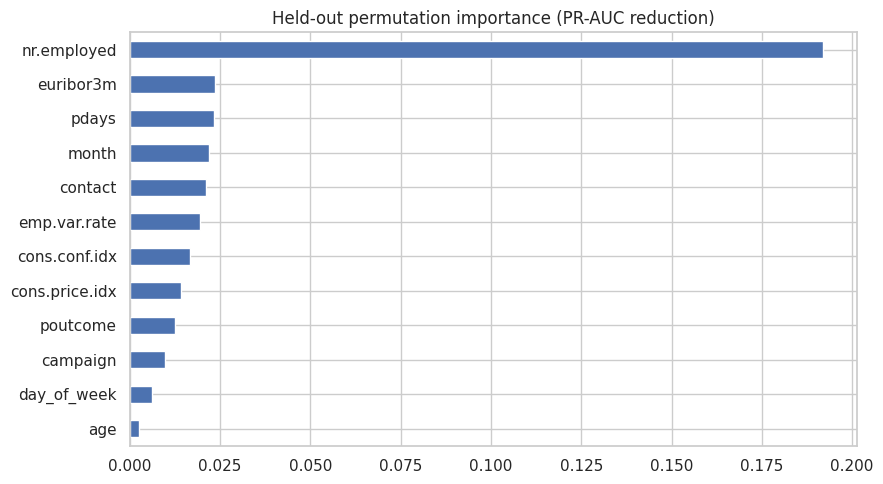

In [10]:
importance=permutation_importance(best,X_test,y_test,scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=-1)
imp=pd.Series(importance.importances_mean,index=X_test.columns).sort_values(ascending=False).head(12)
imp.sort_values().plot.barh(figsize=(9,5),title='Held-out permutation importance (PR-AUC reduction)');plt.tight_layout();plt.show()

## 5. Completed interpretation, limitations and business recommendation

**Class imbalance and baseline.** Of 41,188 records, 4,640 are subscribers (11.27%) and 36,548 are non-subscribers. Predicting the majority class for everyone would appear accurate but would identify no prospective subscribers. Accordingly, PR-AUC and precision–recall trade-offs, not accuracy alone, guide selection.

**Selected approach and evidence.** Gradient boosting leads on validation PR-AUC (0.4697), narrowly ahead of random forest (0.4618) and logistic regression (0.4417). Five-fold CV provides corroborating, but not conclusive, evidence. Held-out test PR-AUC is 0.4826 and ROC-AUC is 0.8081; these estimates should be interpreted with the reported bootstrap intervals and without claiming the small ranking differences are definitive.

**Marketing decision.** The validation-derived 0.175 threshold, under a hypothetical 5:1 missed-subscriber-to-unnecessary-call cost ratio, flags 1,281 validation customers: 548 true subscribers and 733 non-subscribers, while missing 380 subscribers. The threshold illustrates a preference for recovering more potential subscribers at the expense of additional calls. The business must replace this hypothetical cost ratio with measured economics and assess incremental uplift using a randomized campaign before adopting the rule.

**Diagnostics and uncertainty.** The notebook reports a held-out Brier score and reliability plot to evaluate probability calibration, along with subgroup descriptive summaries and permutation importance. These diagnostics can reveal weaknesses but cannot establish fairness, explain causal mechanisms, or certify transferability. In particular, feature importance is a predictive property, not an intervention effect. Bootstrap intervals quantify conditional test-sample uncertainty, not all uncertainty from model selection or retraining.

**Data quality and deployment constraints.** The literal `unknown` entries are treated as missing categorical responses and imputed within training-only pipelines. Twelve exact duplicate records are retained because customer identities are unavailable; this creates possible leakage across a random split. The `duration` field is excluded because it is unavailable before calling; `campaign`, contact timing, and macroeconomic fields must also be audited for availability at the exact decision point. The historical Portuguese campaign data may not generalize to future time periods or another banking population. Chronological out-of-time testing, privacy and consent review, monitoring of subgroup errors, recalibration and prospective evaluation are necessary before deployment.

**Conclusion.** The selected classifier materially improves subscriber prioritization over the majority baseline under this experimental design. It is suitable for further pilot evaluation, **not** as an automatically deployed contact policy or as proof that contacting a predicted subscriber will cause a deposit.

**References**  
Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001  
UCI Machine Learning Repository. *Bank Marketing*. https://archive.ics.uci.edu/dataset/222/bank+marketing  
scikit-learn. *User Guide*. https://scikit-learn.org/stable/user_guide.html

## 6. Final empirical synthesis and answer to the assignment

| Assignment question | Completed evidence-based answer |
|---|---|
| Explore, prepare, and establish a baseline | 41,188 observations, 21 original columns, 11.27% positive target; inspect `unknown` categorical values, retain 12 exact duplicate records with a documented caveat, exclude post-call `duration`, fit imputers/encoders on training folds only. Majority-class validation PR-AUC ≈ 0.1126. |
| Select and rank at most three approaches | **1. Gradient boosting** (validation PR-AUC 0.4697; CV mean ≈ 0.4611); **2. Random forest** (0.4618; ≈ 0.4579); **3. Logistic regression** (0.4417; ≈ 0.4448). Rankings are descriptive and split-dependent. |
| Recommend a threshold and explain trade-offs | **0.175** on validation under an illustrative 5:1 missed-subscriber-to-unnecessary-call cost ratio: TP 548, FP 733, FN 380, 1,281 flagged. Higher threshold means fewer unnecessary calls but more missed subscribers; lower threshold reverses that balance. |

**Independent held-out check.** Gradient boosting achieved test PR-AUC **0.4826**, ROC-AUC **0.8081**, and accuracy **0.8744**. Conditional bootstrap 95% intervals were approximately **[0.452, 0.516]** for PR-AUC and **[0.791, 0.824]** for ROC-AUC. The notebook also displays the final confusion matrix and calibration diagnostics. The test set did not determine model or threshold selection.

**Decision and boundaries.** Use the selected classifier as a candidate for a consent-aware pilot, with a chronological holdout, measured campaign costs, capacity constraints and a randomized uplift test. A predictive association is not evidence that a marketing call will cause a subscription. Subgroup patterns must be evaluated carefully; demographic features may act as proxies and should not be treated as a license for unfair targeting.